In [2]:
!pip install -q torch torchvision
!pip install -q open_clip_torch
!pip install -q ftfy regex tqdm
!pip install -q scikit-learn matplotlib pandas
!pip install -q huggingface_hub
!pip install -q git+https://github.com/apple-aiml-research/ml-mobileclip.git

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [3]:
import torch
import torch.nn as nn
import torch.nn.functional as F

import torchvision
import torchvision.transforms as transforms

import open_clip

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from torch.utils.data import DataLoader
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report
)

import random
import copy
import time
import os

In [4]:
device = "cuda" if torch.cuda.is_available() else "cpu"

print("Using device:", device)

if device == "cuda":
    print(torch.cuda.get_device_name(0))

Using device: cuda
Tesla T4


In [5]:
# download the MobileCLIP2 model

from huggingface_hub import hf_hub_download

checkpoint_path = hf_hub_download(
    repo_id="apple/MobileCLIP2-S0",
    filename="mobileclip2_s0.pt"
)

print("Checkpoint downloaded:", checkpoint_path)

mobileclip2_s0.pt: reconstructing file:   0%|          |  0.00B /  300MB            

mobileclip2_s0.pt: downloading bytes:           |  0.00B            

Checkpoint downloaded: /root/.cache/huggingface/hub/models--apple--MobileCLIP2-S0/snapshots/3136ea51c8ed56b9f9abfab04cb816735aaad6cb/mobileclip2_s0.pt


In [6]:
# Loading the model 

from mobileclip.modules.common.mobileone import reparameterize_model

model_name = "MobileCLIP2-S0"

# S0 requires these image normalization settings.
model_kwargs = {
    "image_mean": (0, 0, 0),
    "image_std": (1, 1, 1)
}

model, _, preprocess = open_clip.create_model_and_transforms(
    model_name,
    pretrained=checkpoint_path,
    **model_kwargs
)

tokenizer = open_clip.get_tokenizer(model_name)

model = model.to(device)

print("MobileCLIP2-S0 loaded successfully!")

/usr/local/lib/python3.13/dist-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)


MobileCLIP2-S0 loaded successfully!


In [7]:
classes = [
    "airplane",
    "automobile",
    "bird",
    "cat",
    "deer",
    "dog",
    "frog",
    "horse",
    "ship",
    "truck"
]

In [8]:
# Obtain input size from the model configuration.
input_size = model.visual.image_size

if isinstance(input_size, (tuple, list)):
    input_size = input_size[-1]

print("Input image size:", input_size)

# Training transformations
train_transform = transforms.Compose([
    transforms.RandomResizedCrop(
        input_size,
        scale=(0.7, 1.0)
    ),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor()
])

# Validation and testing transformations
test_transform = preprocess

Input image size: 256


In [9]:
# loading the dataset

train_dataset = torchvision.datasets.CIFAR10(
    root="./data",
    train=True,
    download=True,
    transform=train_transform
)

test_dataset = torchvision.datasets.CIFAR10(
    root="./data",
    train=False,
    download=True,
    transform=test_transform
)

print("Training images:", len(train_dataset))
print("Testing images:", len(test_dataset))

100%|██████████| 170M/170M [19:41<00:00, 144kB/s]  


Training images: 50000
Testing images: 10000


In [10]:
from torch.utils.data import Subset

# Create a separate dataset using evaluation preprocessing.
train_eval_dataset = torchvision.datasets.CIFAR10(
    root="./data",
    train=True,
    download=True,
    transform=test_transform
)

# Reproducible stratified split
rng = np.random.default_rng(42)

targets = np.array(train_dataset.targets)

train_indices = []
val_indices = []

for class_id in range(10):

    indices = np.where(targets == class_id)[0]

    rng.shuffle(indices)

    val_indices.extend(indices[:500])
    train_indices.extend(indices[500:])

train_subset = Subset(train_dataset, train_indices)
val_subset = Subset(train_eval_dataset, val_indices)

print("Training:", len(train_subset))
print("Validation:", len(val_subset))
print("Testing:", len(test_dataset))

Training: 45000
Validation: 5000
Testing: 10000


In [11]:
BATCH_SIZE = 4

train_loader = DataLoader(
    train_subset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2
)

val_loader = DataLoader(
    val_subset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2
)

In [12]:
prompts = [
    f"a photo of a {name}."
    for name in classes
]

text_tokens = tokenizer(prompts).to(device)

print("Text prompts prepared.")

Text prompts prepared.


In [13]:
# vreate hte text embedding

model.eval()

with torch.no_grad():

    text_features = model.encode_text(text_tokens)

    text_features = F.normalize(
        text_features,
        dim=-1
    )

print("Text embeddings generated:", text_features.shape)

Text embeddings generated: torch.Size([10, 512])


In [14]:
# Zero-shot

# evaluating MobileCLIP2 without training on CIFAR-10

def evaluate_zero_shot(loader):

    model.eval()

    predictions = []
    actual_labels = []

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)

            image_features = model.encode_image(images)

            image_features = F.normalize(
                image_features,
                dim=-1
            )

            similarity = 100.0 * (
                image_features @ text_features.T
            )

            predicted = similarity.argmax(dim=1)

            predictions.extend(predicted.cpu().numpy())
            actual_labels.extend(labels.numpy())

    accuracy = accuracy_score(
        actual_labels,
        predictions
    )

    return accuracy


baseline_accuracy = evaluate_zero_shot(test_loader)

print("Zero-shot accuracy:", baseline_accuracy)

Zero-shot accuracy: 0.9499


Experiment A - Linear Probe
Instead of modifying the entire pretrained model, we can freeze its parameters and train a small classification layer on top of its extracted features.

In [15]:
# Determine the image embedding dimension.

with torch.no_grad():

    dummy_image = torch.randn(
        1, 3, input_size, input_size
    ).to(device)

    feature_dim = model.encode_image(dummy_image).shape[-1]

print("Feature dimension:", feature_dim)


# Classification head
class ClassificationHead(nn.Module):

    def __init__(self, input_dim, num_classes):

        super().__init__()

        self.fc = nn.Linear(
            input_dim,
            num_classes
        )

    def forward(self, x):

        return self.fc(x)


classifier = ClassificationHead(
    feature_dim,
    len(classes)
).to(device)

Feature dimension: 512


In [16]:
# freezing the parameters

for parameter in model.parameters():

    parameter.requires_grad = False

In [17]:
# loss function and optimizer

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW(
    classifier.parameters(),
    lr=0.001,
    weight_decay=0.0001
)

In [18]:
def extract_features(loader):

    model.eval()

    features = []
    labels_list = []

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)

            image_features = model.encode_image(images)

            image_features = F.normalize(
                image_features,
                dim=-1
            )

            features.append(image_features.cpu())
            labels_list.append(labels)

    return (
        torch.cat(features),
        torch.cat(labels_list)
    )


train_features, train_labels = extract_features(train_loader)

val_features, val_labels = extract_features(val_loader)

print("Training features:", train_features.shape)
print("Validation features:", val_features.shape)

Training features: torch.Size([45000, 512])
Validation features: torch.Size([5000, 512])


In [19]:
# train the linear classifier

EPOCHS = 10

for epoch in range(EPOCHS):

    classifier.train()

    permutation = torch.randperm(
        len(train_features)
    )

    total_loss = 0

    for i in range(0, len(permutation), 512):

        indices = permutation[i:i+512]

        batch_features = train_features[indices].to(device)
        batch_labels = train_labels[indices].to(device)

        optimizer.zero_grad()

        outputs = classifier(batch_features)

        loss = criterion(outputs, batch_labels)

        loss.backward()

        optimizer.step()

        total_loss += loss.item()

    print(
        f"Epoch {epoch+1}/{EPOCHS} "
        f"Loss: {total_loss:.4f}"
    )

Epoch 1/10 Loss: 177.9544
Epoch 2/10 Loss: 133.9472
Epoch 3/10 Loss: 100.6719
Epoch 4/10 Loss: 77.3129
Epoch 5/10 Loss: 61.4586
Epoch 6/10 Loss: 50.6305
Epoch 7/10 Loss: 43.0524
Epoch 8/10 Loss: 37.5662
Epoch 9/10 Loss: 33.4719
Epoch 10/10 Loss: 30.3124


In [20]:
def evaluate_linear_probe(features, labels):

    classifier.eval()

    with torch.no_grad():

        features = features.to(device)

        outputs = classifier(features)

        predictions = outputs.argmax(dim=1).cpu().numpy()

    accuracy = accuracy_score(
        labels.numpy(),
        predictions
    )

    return accuracy


linear_accuracy = evaluate_linear_probe(
    val_features,
    val_labels
)

print("Linear probe validation accuracy:", linear_accuracy)

Linear probe validation accuracy: 0.9686


Experiment B - FIne-tuning MobileCLIP2

In [21]:
for parameter in model.parameters():

    parameter.requires_grad = False


# Unfreeze the visual encoder only.
for parameter in model.visual.parameters():

    parameter.requires_grad = True

In [22]:
optimizer = torch.optim.AdamW(

    [
        {
            "params": model.visual.parameters(),
            "lr": 0.00001
        },

        {
            "params": classifier.parameters(),
            "lr": 0.0005
        }
    ],

    weight_decay=0.0001
)

In [23]:
scaler = torch.amp.GradScaler("cuda")

def train_one_epoch():
    model.train()
    classifier.train()

    total_loss = 0
    correct = 0
    total = 0

    optimizer.zero_grad(set_to_none=True)

    for images, labels in train_loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with torch.amp.autocast(
            device_type="cuda",
            dtype=torch.float16
        ):
            features = model.encode_image(images)
            outputs = classifier(features.float())
            loss = criterion(outputs, labels)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        total_loss += loss.item() * labels.size(0)
        predictions = outputs.argmax(dim=1)
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    return total_loss / total, correct / total


In [24]:
def validate():
    model.eval()
    classifier.eval()

    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            with torch.amp.autocast(
                device_type="cuda",
                dtype=torch.float16
            ):
                features = model.encode_image(images)
                outputs = classifier(features.float())

            predictions = outputs.argmax(dim=1)
            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    return correct / total

In [ ]:
EPOCHS = 5

best_accuracy = 0

best_model_state = None
best_classifier_state = None

training_history = []

for epoch in range(EPOCHS):

    loss, train_accuracy = train_one_epoch()

    val_accuracy = validate()

    training_history.append({
        "epoch": epoch + 1,
        "loss": loss,
        "train_accuracy": train_accuracy,
        "validation_accuracy": val_accuracy
    })

    print(
        f"Epoch {epoch+1}/{EPOCHS} | "
        f"Loss: {loss:.4f} | "
        f"Train Accuracy: {train_accuracy:.4f} | "
        f"Validation Accuracy: {val_accuracy:.4f}"
    )

    if val_accuracy > best_accuracy:

        best_accuracy = val_accuracy

        best_model_state = copy.deepcopy(
            model.state_dict()
        )

        best_classifier_state = copy.deepcopy(
            classifier.state_dict()
        )


# Restore the best validation checkpoint.
model.load_state_dict(best_model_state)

classifier.load_state_dict(best_classifier_state)

print("Best validation accuracy:", best_accuracy)

Epoch 1/5 | Loss: 0.3490 | Train Accuracy: 0.8848 | Validation Accuracy: 0.9460
Epoch 2/5 | Loss: 0.1842 | Train Accuracy: 0.9380 | Validation Accuracy: 0.9580
Epoch 3/5 | Loss: 0.1429 | Train Accuracy: 0.9516 | Validation Accuracy: 0.9686
Epoch 4/5 | Loss: 0.1113 | Train Accuracy: 0.9627 | Validation Accuracy: 0.9674


In [26]:
def evaluate_model(loader):

    model.eval()
    classifier.eval()

    predictions = []
    actual = []

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)

            features = model.encode_image(images)

            features = F.normalize(
                features,
                dim=-1
            )

            outputs = classifier(features)

            predicted = outputs.argmax(dim=1)

            predictions.extend(
                predicted.cpu().numpy()
            )

            actual.extend(labels.numpy())

    accuracy = accuracy_score(actual, predictions)

    precision, recall, f1, _ = precision_recall_fscore_support(
        actual,
        predictions,
        average="macro",
        zero_division=0
    )

    return {
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-score": f1
    }


finetuned_results = evaluate_model(test_loader)

print(finetuned_results)

{'Accuracy': 0.9684, 'Precision': 0.9685181870443721, 'Recall': 0.9683999999999999, 'F1-score': 0.9683843335706162}


In [27]:
def generate_classification_report(loader):

    model.eval()
    classifier.eval()

    predictions = []
    actual = []

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)

            features = model.encode_image(images)

            features = F.normalize(
                features,
                dim=-1
            )

            outputs = classifier(features)

            predicted = outputs.argmax(dim=1)

            predictions.extend(
                predicted.cpu().numpy()
            )

            actual.extend(labels.numpy())

    print(
        classification_report(
            actual,
            predictions,
            target_names=classes
        )
    )


generate_classification_report(test_loader)

              precision    recall  f1-score   support

    airplane       0.98      0.96      0.97      1000
  automobile       0.98      0.98      0.98      1000
        bird       0.96      0.97      0.97      1000
         cat       0.95      0.92      0.93      1000
        deer       0.97      0.97      0.97      1000
         dog       0.93      0.96      0.94      1000
        frog       0.98      0.98      0.98      1000
       horse       0.97      0.98      0.98      1000
        ship       0.98      0.98      0.98      1000
       truck       0.98      0.98      0.98      1000

    accuracy                           0.97     10000
   macro avg       0.97      0.97      0.97     10000
weighted avg       0.97      0.97      0.97     10000



In [28]:
results = pd.DataFrame([

    {
        "Model": "MobileCLIP2 Zero-Shot",
        "Accuracy": baseline_accuracy
    },

    {
        "Model": "Linear Probe",
        "Accuracy": linear_accuracy
    },

    {
        "Model": "Fine-Tuned MobileCLIP2",
        "Accuracy": finetuned_results["Accuracy"]
    }

])

display(results)

,Model,Accuracy
0,MobileCLIP2 Zero-Shot,0.9499
1,Linear Probe,0.9686
2,Fine-Tuned MobileCLIP2,0.9684


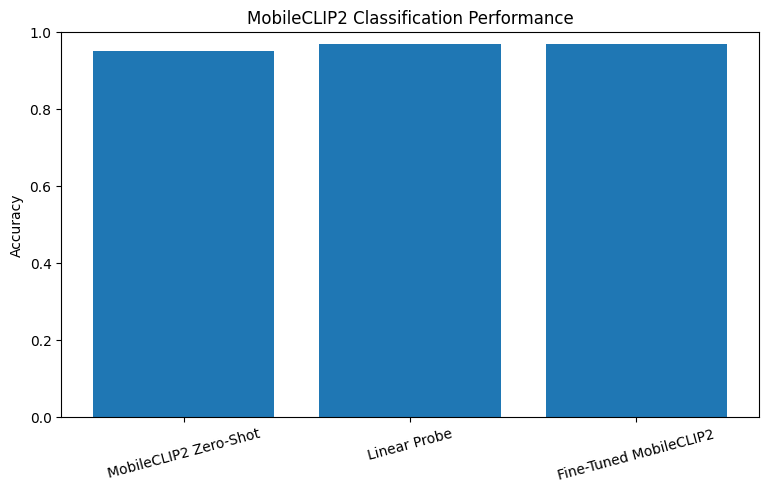

In [29]:
plt.figure(figsize=(9, 5))

plt.bar(
    results["Model"],
    results["Accuracy"]
)

plt.title("MobileCLIP2 Classification Performance")

plt.ylabel("Accuracy")

plt.ylim(0, 1)

plt.xticks(rotation=15)

plt.show()

In [30]:
torch.save({

    "model_state_dict": model.state_dict(),

    "classifier_state_dict": classifier.state_dict(),

    "classes": classes,

    "model_name": "MobileCLIP2-S0"

}, "mobileclip2_finetuned_cifar10.pth")


print("Fine-tuned model saved!")

Fine-tuned model saved!


Model Preparation for smartphone deployment

In [31]:
import copy

model.eval()

# Make a separate copy for deployment.
deployment_model = copy.deepcopy(model)

# Reparameterize for inference.
deployment_model = reparameterize_model(
    deployment_model
)

deployment_model.eval()

CustomTextCLIP(
  (visual): TimmModel(
    (trunk): FastVit(
      (stem): Sequential(
        (0): MobileOneBlock(
          (se): Identity()
          (act): GELU(approximate='none')
          (reparam_conv): Conv2d(3, 64, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
        )
        (1): MobileOneBlock(
          (se): Identity()
          (act): GELU(approximate='none')
          (reparam_conv): Conv2d(64, 64, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), groups=64)
        )
        (2): MobileOneBlock(
          (se): Identity()
          (act): GELU(approximate='none')
          (reparam_conv): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1))
        )
      )
      (stages): Sequential(
        (0): FastVitStage(
          (downsample): Identity()
          (pos_emb): Identity()
          (blocks): Sequential(
            (0): RepMixerBlock(
              (token_mixer): RepMixer(
                (reparam_conv): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padd

In [32]:
class MobileCLIPClassifier(nn.Module):

    def __init__(self, clip_model, classifier):

        super().__init__()

        self.clip_model = clip_model

        self.classifier = classifier


    def forward(self, images):

        features = self.clip_model.encode_image(images)

        features = F.normalize(
            features,
            dim=-1
        )

        outputs = self.classifier(features)

        return outputs


mobile_model = MobileCLIPClassifier(
    deployment_model,
    copy.deepcopy(classifier)
).eval().to(device)

In [33]:
example_input = torch.randn(
    1,
    3,
    input_size,
    input_size
).to(device)

traced_model = torch.jit.trace(
    mobile_model,
    example_input
)

traced_model.save(
    "mobileclip2_android.pt"
)

print("TorchScript export completed.")

TorchScript export completed.


Benchmark Inference Performance

In [34]:
import time

mobile_model.eval()

sample = torch.randn(
    1,
    3,
    input_size,
    input_size
).to(device)

# Warm-up
with torch.no_grad():

    for _ in range(20):
        mobile_model(sample)

if device == "cuda":
    torch.cuda.synchronize()

# Actual measurement
times = []

with torch.no_grad():

    for _ in range(100):

        start = time.perf_counter()

        mobile_model(sample)

        if device == "cuda":
            torch.cuda.synchronize()

        end = time.perf_counter()

        times.append((end - start) * 1000)


print("Average latency:", np.mean(times), "ms")
print("Median latency:", np.median(times), "ms")
print("90th percentile:", np.percentile(times, 90), "ms")

Average latency: 9.221460490007303 ms
Median latency: 9.075874999780353 ms
90th percentile: 9.832681299940305 ms


In [35]:
model_path = "mobileclip2_finetuned_cifar10.pth"

size_bytes = os.path.getsize(model_path)

size_mb = size_bytes / (1024 * 1024)

print("Model size:", round(size_mb, 2), "MB")

Model size: 286.08 MB
